# Time-domain audio feature Extraction

written by Seetha Parameswaran for Audio Analytics course offered at BITS Pilani.

This comprehensive Python program for **Lab 2** implements all three required time-domain audio features with professional-grade code structure. Here's what it provides:

## **Core Features Implemented:**

### **1. Amplitude Envelope Feature**
- **Definition**: Maximum absolute value within each frame
- **Purpose**: Shows overall amplitude variation over time
- **Application**: Speech activity detection, dynamic range analysis

### **2. Root-Mean Square Energy**
- **Definition**: √(mean(x²)) for each frame
- **Purpose**: Measures signal power/energy over time
- **Application**: Audio segmentation, energy-based classification

### **3. Zero Crossing Rate**
- **Definition**: Rate of sign changes in the signal
- **Purpose**: Distinguishes periodic vs. noise-like signals
- **Application**: Voiced/unvoiced speech detection, texture analysis

## **Key Program Components:**

### **1. TimeDomainFeatureExtractor Class**
- **Modular design** for easy reuse and extension
- **Consistent interface** for all three features
- **Configurable parameters** (frame_length, hop_length)
- **Professional documentation** with clear explanations

### **2. Multiple Test Signals**
- **Pure sine wave**: Low ZCR, steady envelope/RMS
- **AM signal**: Varying envelope, demonstrates modulation
- **Chirp signal**: Frequency sweep, changing characteristics
- **Noisy signal**: High ZCR, variable energy
- **Speech-like**: Alternating voiced/unvoiced segments

### **3. Comprehensive Analysis**
- **Visual plots**: 4-panel display showing original signal + 3 features
- **Statistical summary**: Mean, std, min, max for each feature
- **Feature comparison**: Cross-signal analysis
- **Data export**: CSV files for further analysis

### **4. Professional Features**
- **Error handling**: Robust file loading
- **Data export**: CSV format for external analysis
- **Visualization**: Publication-quality plots
- **Code documentation**: Clear comments and docstrings

 
### **For Audio Files:**
```python
# Load audio file
audio_data, sample_rate = librosa.load("your_audio.wav")

# Extract features
extractor = TimeDomainFeatureExtractor(sample_rate)
features = extractor.extract_all_features(audio_data)
```

## **Expected Output:**

1. **Visual Analysis**: 4-panel plots for each signal type
2. **Statistical Reports**: Numerical summaries of feature characteristics
3. **CSV Files**: Exportable data for further analysis
4. **Comparison Plots**: Cross-signal feature comparison

## **Learning Benefits:**

- **Hands-on Implementation**: Understanding feature extraction algorithms
- **Signal Analysis**: Comparing different signal types
- **Professional Coding**: Industry-standard code structure
- **Data Visualization**: Effective presentation of results
- **Feature Interpretation**: Understanding what each feature represents



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import read, write
from scipy import signal
import librosa
import os

In [2]:
class TimeDomainFeatureExtractor:
    """
    Class for extracting time-domain audio features.
    """
    
    def __init__(self, sample_rate=44100):
        self.sample_rate = sample_rate
    
    def amplitude_envelope(self, audio_signal, frame_length=2048, hop_length=512):
        """
        Extract amplitude envelope feature.
        
        The amplitude envelope represents the outline of the waveform,
        showing how the amplitude varies over time.
        
        Parameters:
        - audio_signal: 1D numpy array
        - frame_length: size of analysis frame
        - hop_length: step size between frames
        
        Returns:
        - envelope: amplitude envelope values
        - time_frames: corresponding time stamps
        """
        # Ensure signal is 1D
        if audio_signal.ndim > 1:
            audio_signal = audio_signal.flatten()
        
        # Calculate number of frames
        n_frames = 1 + (len(audio_signal) - frame_length) // hop_length
        
        envelope = np.zeros(n_frames)
        time_frames = np.zeros(n_frames)
        
        for i in range(n_frames):
            start = i * hop_length
            end = min(start + frame_length, len(audio_signal))
            frame = audio_signal[start:end]
            
            # Amplitude envelope is the maximum absolute value in each frame
            envelope[i] = np.max(np.abs(frame))
            time_frames[i] = (start + end) / 2  # Frame center
        
        return envelope, time_frames
    
    def rms_energy(self, audio_signal, frame_length=2048, hop_length=512):
        """
        Extract Root-Mean Square Energy.
        
        RMS Energy provides a measure of the signal's power over time.
        
        Parameters:
        - audio_signal: 1D numpy array
        - frame_length: size of analysis frame
        - hop_length: step size between frames
        
        Returns:
        - rms: RMS energy values
        - time_frames: corresponding time stamps
        """
        # Ensure signal is 1D
        if audio_signal.ndim > 1:
            audio_signal = audio_signal.flatten()
        
        # Calculate number of frames
        n_frames = 1 + (len(audio_signal) - frame_length) // hop_length
        
        rms = np.zeros(n_frames)
        time_frames = np.zeros(n_frames)
        
        for i in range(n_frames):
            start = i * hop_length
            end = min(start + frame_length, len(audio_signal))
            frame = audio_signal[start:end]
            
            # RMS Energy calculation
            rms[i] = np.sqrt(np.mean(frame**2))
            time_frames[i] = (start + end) / 2  # Frame center
        
        return rms, time_frames
    
    def zero_crossing_rate(self, audio_signal, frame_length=2048, hop_length=512):
        """
        Extract Zero Crossing Rate.
        
        ZCR measures how frequently the signal crosses zero,
        useful for distinguishing voiced/unvoiced speech and signal types.
        
        Parameters:
        - audio_signal: 1D numpy array
        - frame_length: size of analysis frame
        - hop_length: step size between frames
        
        Returns:
        - zcr: zero crossing rate values
        - time_frames: corresponding time stamps
        """
        # Ensure signal is 1D
        if audio_signal.ndim > 1:
            audio_signal = audio_signal.flatten()
        
        # Calculate number of frames
        n_frames = 1 + (len(audio_signal) - frame_length) // hop_length
        
        zcr = np.zeros(n_frames)
        time_frames = np.zeros(n_frames)
        
        for i in range(n_frames):
            start = i * hop_length
            end = min(start + frame_length, len(audio_signal))
            frame = audio_signal[start:end]
            
            # ZCR calculation
            sign_changes = np.sum(np.abs(np.diff(np.sign(frame))))
            zcr[i] = sign_changes / (2.0 * len(frame))
            time_frames[i] = (start + end) / 2  # Frame center
        
        return zcr, time_frames
    
    def extract_all_features(self, audio_signal, frame_length=2048, hop_length=512):
        """
        Extract all three time-domain features.
        
        Parameters:
        - audio_signal: 1D numpy array
        - frame_length: size of analysis frame
        - hop_length: step size between frames
        
        Returns:
        - features: dictionary containing all features and time stamps
        """
        # Extract individual features
        amp_env, time_env = self.amplitude_envelope(audio_signal, frame_length, hop_length)
        rms_vals, time_rms = self.rms_energy(audio_signal, frame_length, hop_length)
        zcr_vals, time_zcr = self.zero_crossing_rate(audio_signal, frame_length, hop_length)
        
        # Package results
        features = {
            'amplitude_envelope': amp_env,
            'rms_energy': rms_vals,
            'zero_crossing_rate': zcr_vals,
            'time_frames': time_env,  # All should have same time frames
            'frame_length': frame_length,
            'hop_length': hop_length,
            'sample_rate': self.sample_rate
        }
        
        return features

In [3]:
def analyze_audio_file(file_path):
    """Analyze features from an actual audio file."""
    
    try:
        # Try to load with librosa (handles more formats)
        audio_data, sample_rate = librosa.load(file_path, sr=None)
        print(f"Loaded audio file: {file_path}")
        print(f"Duration: {len(audio_data)/sample_rate:.2f} seconds")
        print(f"Sample rate: {sample_rate} Hz")
        return audio_data, sample_rate
    
    except Exception as e:
        print(f"Error loading audio file: {e}")
        return None, None


In [4]:
def plot_features(audio_signal, features, signal_name, sample_rate, time_axis=None):
    """Plot the audio signal and its extracted features."""
    
    # Convert frame indices to time
    time_features = features['time_frames'] / sample_rate
    
    # Create time axis for original signal if not provided
    if time_axis is None:
        time_axis = np.arange(len(audio_signal)) / sample_rate
    
    # Create figure
    fig, axes = plt.subplots(4, 1, figsize=(12, 10))
    
    # Plot original signal
    axes[0].plot(time_axis, audio_signal, 'b-', linewidth=0.5)
    axes[0].set_title(f'{signal_name} - Original Waveform')
    axes[0].set_xlabel('Time (s)')
    axes[0].set_ylabel('Amplitude')
    axes[0].grid(True, alpha=0.3)
    
    # Plot amplitude envelope
    axes[1].plot(time_features, features['amplitude_envelope'], 'r-', linewidth=2)
    axes[1].fill_between(time_features, features['amplitude_envelope'], alpha=0.3)
    axes[1].set_title('Amplitude Envelope')
    axes[1].set_xlabel('Time (s)')
    axes[1].set_ylabel('Amplitude')
    axes[1].grid(True, alpha=0.3)
    
    # Plot RMS energy
    axes[2].plot(time_features, features['rms_energy'], 'g-', linewidth=2)
    axes[2].fill_between(time_features, features['rms_energy'], alpha=0.3)
    axes[2].set_title('RMS Energy')
    axes[2].set_xlabel('Time (s)')
    axes[2].set_ylabel('RMS Energy')
    axes[2].grid(True, alpha=0.3)
    
    # Plot zero crossing rate
    axes[3].plot(time_features, features['zero_crossing_rate'], 'm-', linewidth=2)
    axes[3].set_title('Zero Crossing Rate')
    axes[3].set_xlabel('Time (s)')
    axes[3].set_ylabel('ZCR')
    axes[3].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return fig

In [5]:
def print_feature_statistics(features, signal_name):
    """Print statistical summary of extracted features."""
    
    print(f"\n{signal_name} - Feature Statistics:")
    print("=" * 50)
    
    # Amplitude Envelope Statistics
    amp_env = features['amplitude_envelope']
    print(f"Amplitude Envelope:")
    print(f"  Mean: {np.mean(amp_env):.4f}")
    print(f"  Std:  {np.std(amp_env):.4f}")
    print(f"  Max:  {np.max(amp_env):.4f}")
    print(f"  Min:  {np.min(amp_env):.4f}")
    
    # RMS Energy Statistics  
    rms = features['rms_energy']
    print(f"RMS Energy:")
    print(f"  Mean: {np.mean(rms):.4f}")
    print(f"  Std:  {np.std(rms):.4f}")
    print(f"  Max:  {np.max(rms):.4f}")
    print(f"  Min:  {np.min(rms):.4f}")
    
    # Zero Crossing Rate Statistics
    zcr = features['zero_crossing_rate']
    print(f"Zero Crossing Rate:")
    print(f"  Mean: {np.mean(zcr):.4f}")
    print(f"  Std:  {np.std(zcr):.4f}")
    print(f"  Max:  {np.max(zcr):.4f}")
    print(f"  Min:  {np.min(zcr):.4f}")
    
    print("-" * 50)

In [6]:
def save_features_to_file(features, signal_name, filename):
    """Save extracted features to a CSV file."""
    
    # Convert frame indices to time
    time_sec = features['time_frames'] / features['sample_rate']
    
    # Create data array
    data = np.column_stack([
        time_sec,
        features['amplitude_envelope'],
        features['rms_energy'],
        features['zero_crossing_rate']
    ])
    
    # Save to CSV
    header = "Time(s),Amplitude_Envelope,RMS_Energy,Zero_Crossing_Rate"
    np.savetxt(filename, data, delimiter=',', header=header, comments='')
    
    print(f"Features saved to: {filename}")

In [7]:
def compare_features_across_signals(all_features, signal_names):
    """Compare features across different signal types."""
    
    fig, axes = plt.subplots(3, 1, figsize=(12, 10))
    colors = ['red', 'blue', 'green', 'orange', 'purple']
    
    for i, (signal_name, features) in enumerate(zip(signal_names, all_features)):
        time_features = features['time_frames'] / features['sample_rate']
        color = colors[i % len(colors)]
        
        # Plot amplitude envelope
        axes[0].plot(time_features, features['amplitude_envelope'], 
                    color=color, label=signal_name, linewidth=1)
        
        # Plot RMS energy
        axes[1].plot(time_features, features['rms_energy'], 
                    color=color, label=signal_name, linewidth=1)
        
        # Plot zero crossing rate
        axes[2].plot(time_features, features['zero_crossing_rate'], 
                    color=color, label=signal_name, linewidth=1)
    
    axes[0].set_title('Amplitude Envelope Comparison')
    axes[0].set_ylabel('Amplitude')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].set_title('RMS Energy Comparison')
    axes[1].set_ylabel('RMS Energy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    axes[2].set_title('Zero Crossing Rate Comparison')
    axes[2].set_xlabel('Time (s)')
    axes[2].set_ylabel('ZCR')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [11]:
"""Generate various test signals for demonstration."""

sample_rate = 44100
duration = 3.0
time_axis = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)

signals = {}

# 1. Pure sine wave (440 Hz - A4)
signals['Pure Sine Wave (A4)'] = np.sin(2 * np.pi * 440 * time_axis)

# 2. Amplitude modulated sine wave
carrier = np.sin(2 * np.pi * 440 * time_axis)
modulator = 0.5 * (1 + np.sin(2 * np.pi * 2 * time_axis))  # 2 Hz AM
signals['AM Sine Wave'] = modulator * carrier

# 3. Chirp signal (frequency sweep)
signals['Chirp Signal'] = signal.chirp(time_axis, f0=200, f1=800, t1=duration, method='linear')

# 4. Noisy signal
np.random.seed(42)
noise = np.random.normal(0, 0.1, len(time_axis))
signals['Noisy Sine'] = np.sin(2 * np.pi * 440 * time_axis) + noise

# 5. Speech-like signal (voiced + unvoiced)
speech_like = np.zeros_like(time_axis)
segment_length = len(time_axis) // 6

for i in range(6):
    start = i * segment_length
    end = min((i + 1) * segment_length, len(time_axis))
    if i % 2 == 0:  # Voiced segments
        speech_like[start:end] = 0.7 * np.sin(2 * np.pi * 150 * time_axis[start:end])
    else:  # Unvoiced segments (noise)
        speech_like[start:end] = 0.3 * np.random.normal(0, 1, end - start)

signals['Speech-like Signal'] = speech_like



In [12]:
# Initialize feature extractor
extractor = TimeDomainFeatureExtractor(sample_rate=44100)


In [13]:
signal_names = list(signals.keys()) 


Processing:  Pure Sine Wave (A4)


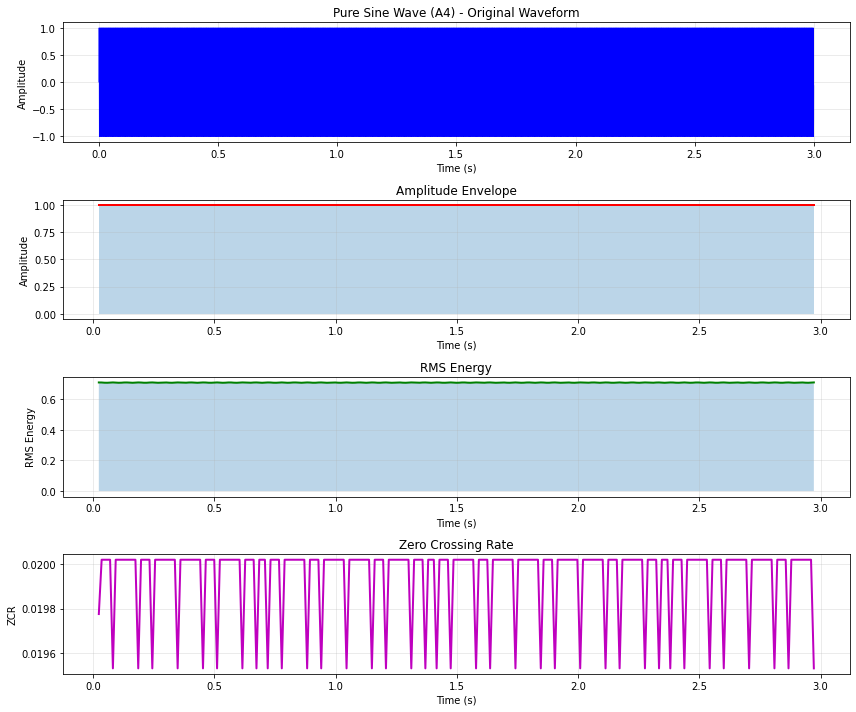


Pure Sine Wave (A4) - Feature Statistics:
Amplitude Envelope:
  Mean: 1.0000
  Std:  0.0000
  Max:  1.0000
  Min:  1.0000
RMS Energy:
  Mean: 0.7071
  Std:  0.0008
  Max:  0.7082
  Min:  0.7060
Zero Crossing Rate:
  Mean: 0.0199
  Std:  0.0002
  Max:  0.0200
  Min:  0.0195
--------------------------------------------------

Generating analysis plots for Audio Signal...


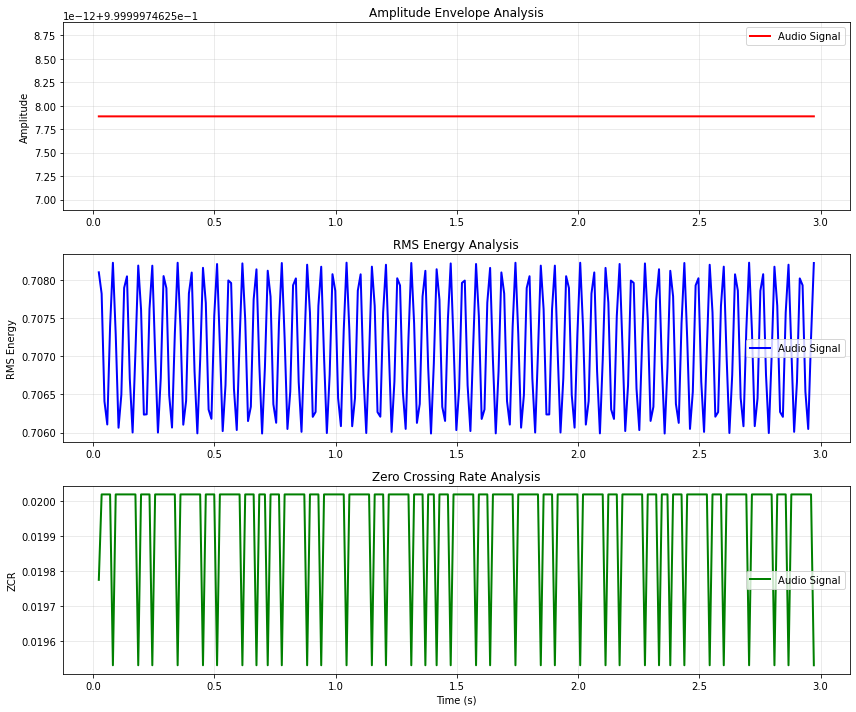

In [14]:
signal_name = signal_names[0]
audio_signal = signals[signal_name ]

# Process chirp signal specifically
print("\nProcessing: ", signal_name)

# Extract features for  signal
audio_features = extractor.extract_all_features(
    audio_signal, 
    frame_length=2048, 
    hop_length=512
)

# Plot features for  signal
plot_features(audio_signal, audio_features, signal_name, sample_rate, time_axis)

# Print statistics for  signal
print_feature_statistics(audio_features, signal_name)

# Save features to file for  signal
# save_features_to_file(audio_features, signal_name, "features_Signal.csv")

# Store for comparison
all_features = [audio_features]

# Compare features  
print("\nGenerating analysis plots for Audio Signal...")

# Create individual feature analysis plots
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
time_features = audio_features['time_frames'] / sample_rate

# Plot amplitude envelope
axes[0].plot(time_features, audio_features['amplitude_envelope'], 
            'red', label='Audio Signal', linewidth=2)
axes[0].set_title('Amplitude Envelope Analysis')
axes[0].set_ylabel('Amplitude')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot RMS energy
axes[1].plot(time_features, audio_features['rms_energy'], 
            'blue', label='Audio Signal', linewidth=2)
axes[1].set_title('RMS Energy Analysis')
axes[1].set_ylabel('RMS Energy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot zero crossing rate
axes[2].plot(time_features, audio_features['zero_crossing_rate'], 
            'green', label='Audio Signal', linewidth=2)
axes[2].set_title('Zero Crossing Rate Analysis')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('ZCR')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
def generate_test_signals():
    """Generate various test signals for demonstration."""
    
    sample_rate = 44100
    duration = 3.0
    t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)
    
    signals = {}
    
    # 1. Pure sine wave (440 Hz - A4)
    signals['Pure Sine Wave (A4)'] = np.sin(2 * np.pi * 440 * t)
    
    # 2. Amplitude modulated sine wave
    carrier = np.sin(2 * np.pi * 440 * t)
    modulator = 0.5 * (1 + np.sin(2 * np.pi * 2 * t))  # 2 Hz AM
    signals['AM Sine Wave'] = modulator * carrier
    
    # 3. Chirp signal (frequency sweep)
    signals['Chirp Signal'] = signal.chirp(t, f0=200, f1=800, t1=duration, method='linear')
    
    # 4. Noisy signal
    np.random.seed(42)
    noise = np.random.normal(0, 0.1, len(t))
    signals['Noisy Sine'] = np.sin(2 * np.pi * 440 * t) + noise
    
    # 5. Speech-like signal (voiced + unvoiced)
    speech_like = np.zeros_like(t)
    segment_length = len(t) // 6
    
    for i in range(6):
        start = i * segment_length
        end = min((i + 1) * segment_length, len(t))
        if i % 2 == 0:  # Voiced segments
            speech_like[start:end] = 0.7 * np.sin(2 * np.pi * 150 * t[start:end])
        else:  # Unvoiced segments (noise)
            speech_like[start:end] = 0.3 * np.random.normal(0, 1, end - start)
    
    signals['Speech-like Signal'] = speech_like
    
    return signals, sample_rate, t


Generating test signals...

Processing: Pure Sine Wave (A4)


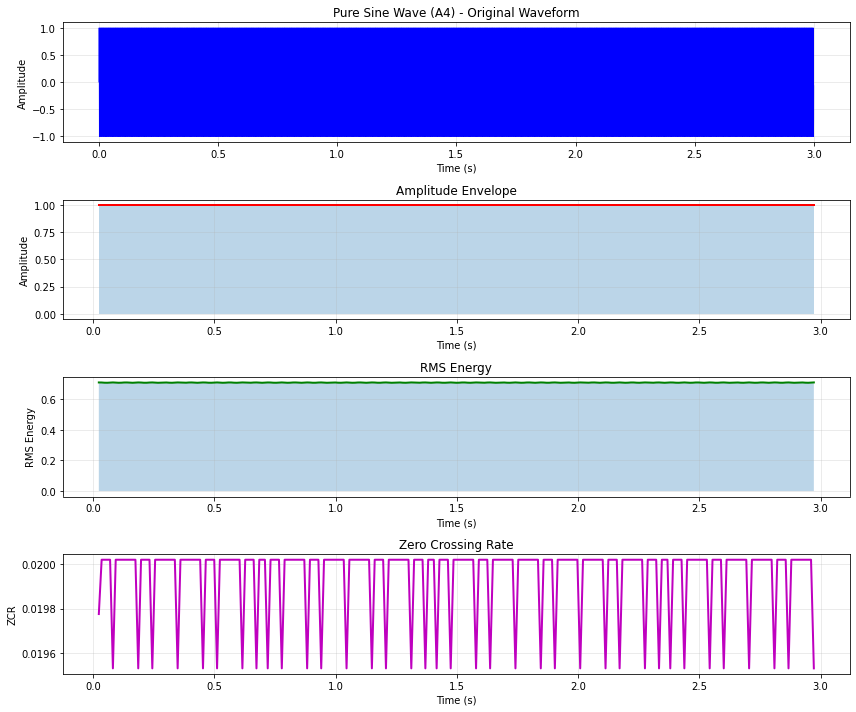


Pure Sine Wave (A4) - Feature Statistics:
Amplitude Envelope:
  Mean: 1.0000
  Std:  0.0000
  Max:  1.0000
  Min:  1.0000
RMS Energy:
  Mean: 0.7071
  Std:  0.0008
  Max:  0.7082
  Min:  0.7060
Zero Crossing Rate:
  Mean: 0.0199
  Std:  0.0002
  Max:  0.0200
  Min:  0.0195
--------------------------------------------------

Processing: AM Sine Wave


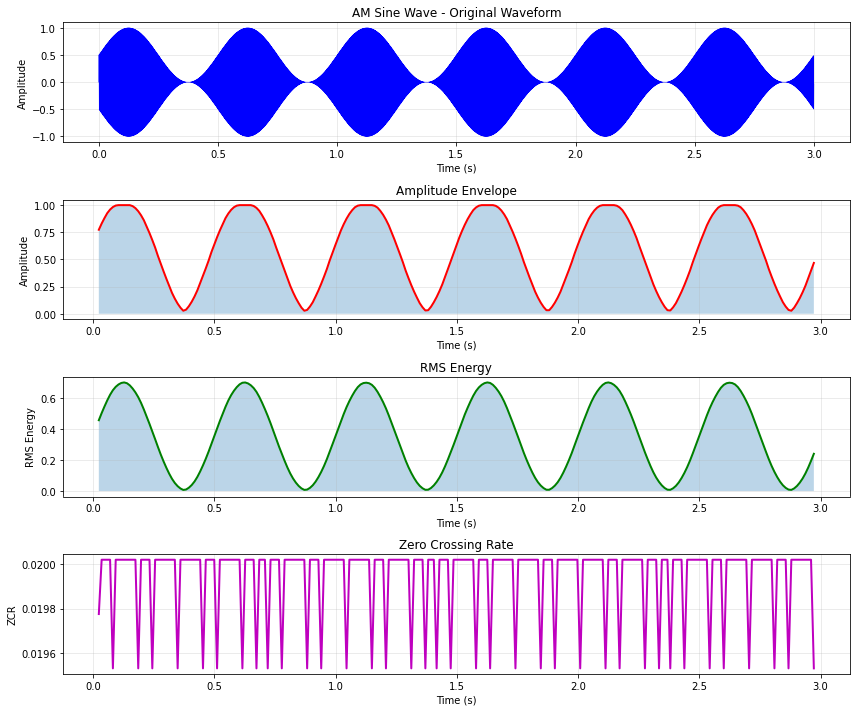


AM Sine Wave - Feature Statistics:
Amplitude Envelope:
  Mean: 0.5896
  Std:  0.3447
  Max:  0.9997
  Min:  0.0279
RMS Energy:
  Mean: 0.3578
  Std:  0.2456
  Max:  0.7027
  Min:  0.0074
Zero Crossing Rate:
  Mean: 0.0199
  Std:  0.0002
  Max:  0.0200
  Min:  0.0195
--------------------------------------------------

Processing: Chirp Signal


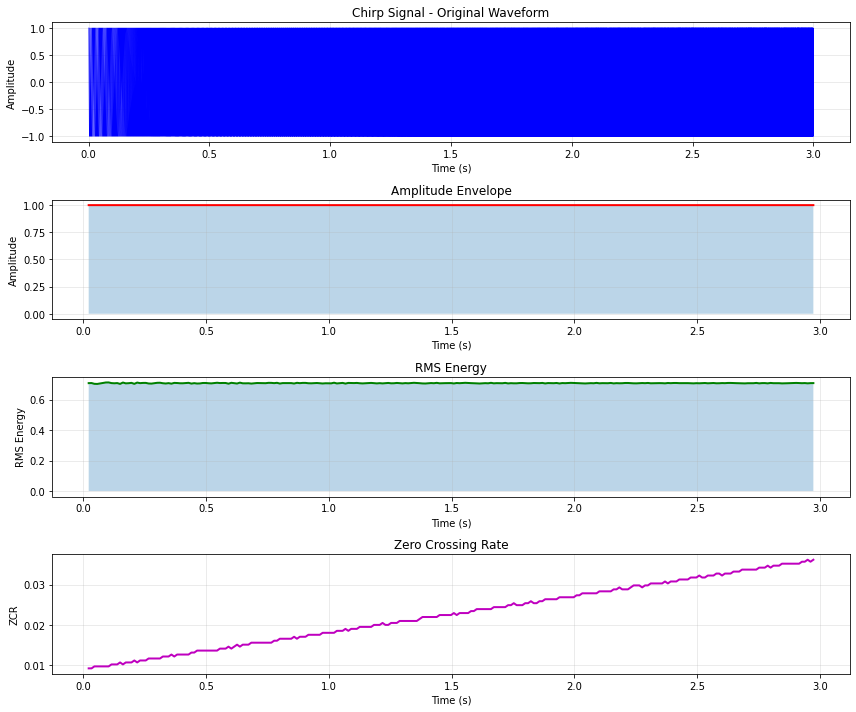


Chirp Signal - Feature Statistics:
Amplitude Envelope:
  Mean: 1.0000
  Std:  0.0000
  Max:  1.0000
  Min:  1.0000
RMS Energy:
  Mean: 0.7071
  Std:  0.0015
  Max:  0.7119
  Min:  0.7020
Zero Crossing Rate:
  Mean: 0.0226
  Std:  0.0078
  Max:  0.0361
  Min:  0.0093
--------------------------------------------------

Processing: Noisy Sine


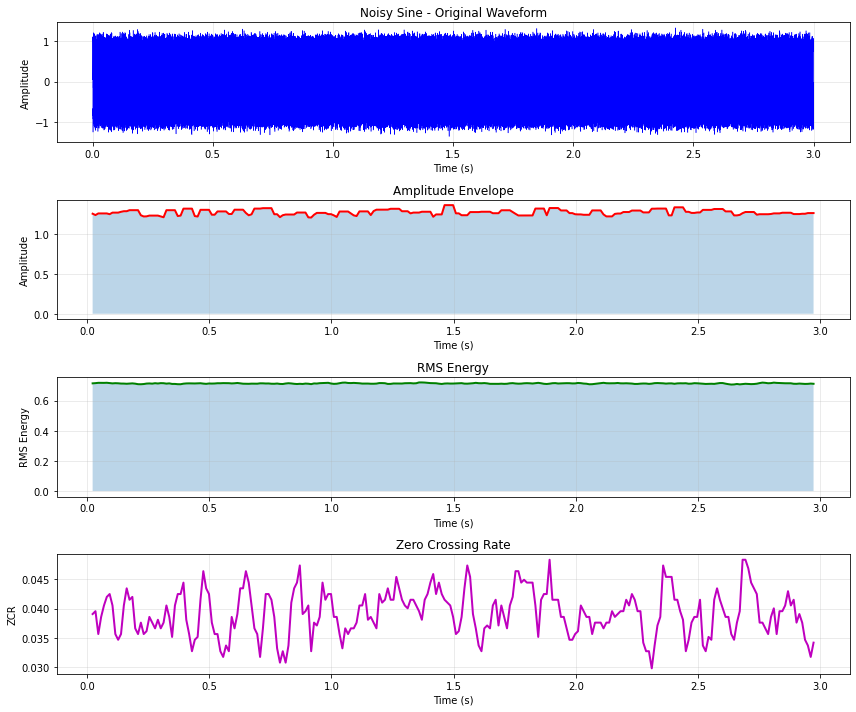


Noisy Sine - Feature Statistics:
Amplitude Envelope:
  Mean: 1.2785
  Std:  0.0328
  Max:  1.3673
  Min:  1.2110
RMS Energy:
  Mean: 0.7142
  Std:  0.0025
  Max:  0.7210
  Min:  0.7069
Zero Crossing Rate:
  Mean: 0.0392
  Std:  0.0038
  Max:  0.0483
  Min:  0.0298
--------------------------------------------------

Processing: Speech-like Signal


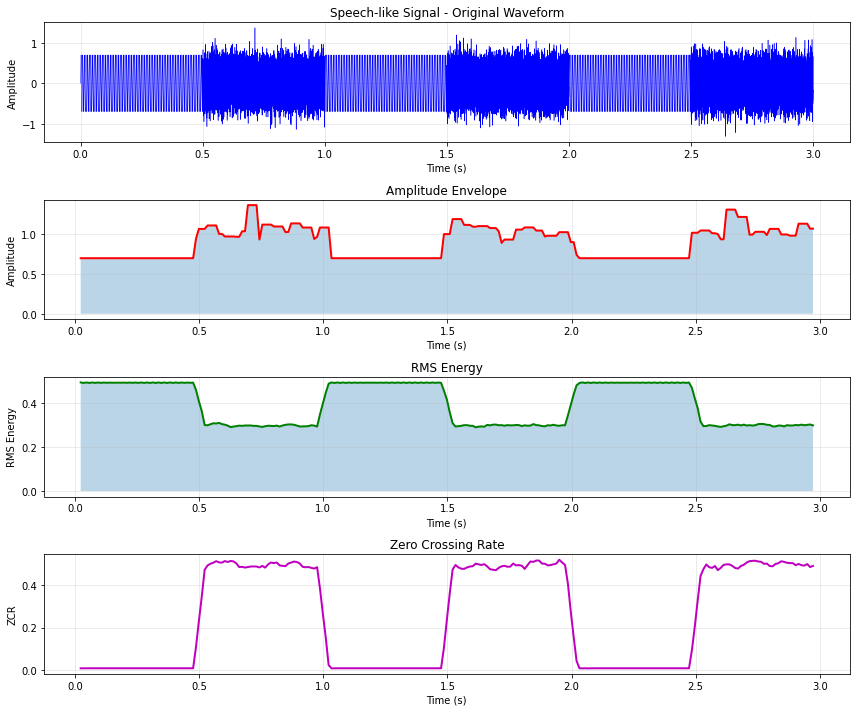


Speech-like Signal - Feature Statistics:
Amplitude Envelope:
  Mean: 0.8975
  Std:  0.1977
  Max:  1.3686
  Min:  0.7000
RMS Energy:
  Mean: 0.3980
  Std:  0.0952
  Max:  0.4962
  Min:  0.2911
Zero Crossing Rate:
  Mean: 0.2512
  Std:  0.2386
  Max:  0.5215
  Min:  0.0063
--------------------------------------------------

Generating comparison plots...


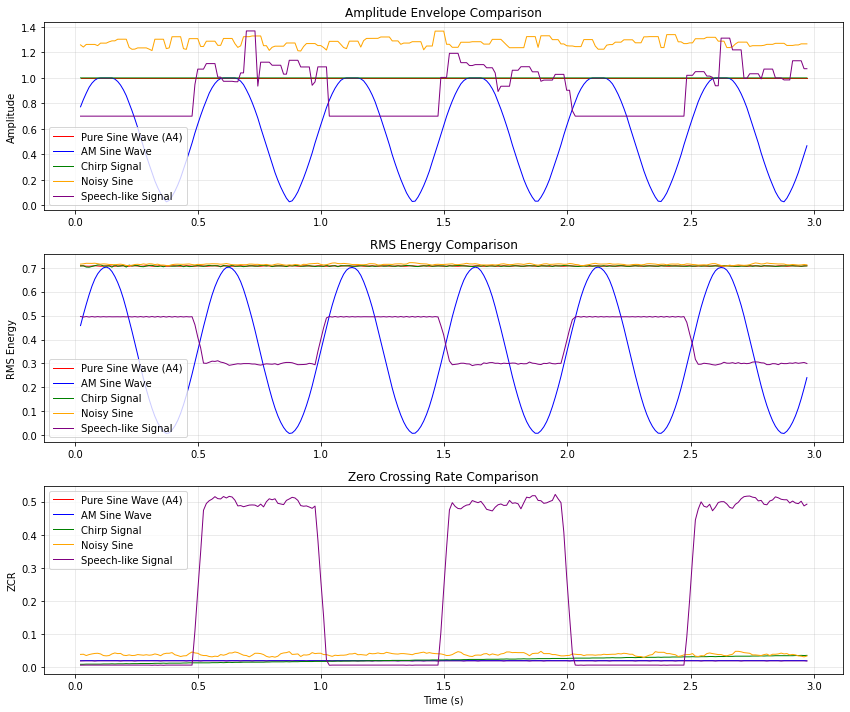

'\naudio_file = "path_to_your_audio_file.wav"  # Replace with actual file path\nif os.path.exists(audio_file):\n    print(f"\nAnalyzing audio file: {audio_file}")\n    audio_data, sr = analyze_audio_file(audio_file)\n    if audio_data is not None:\n        extractor.sample_rate = sr\n        features = extractor.extract_all_features(audio_data)\n        plot_features(audio_data, features, "Audio File", sr)\n        print_feature_statistics(features, "Audio File")\n'

In [16]:
# Initialize feature extractor
extractor = TimeDomainFeatureExtractor(sample_rate=44100)

# Generate test signals
print("\nGenerating test signals...")
test_signals, sample_rate, time_axis = generate_test_signals()

# Process each signal
all_features = []
signal_names = list(test_signals.keys())

for signal_name, audio_signal in test_signals.items():
    print(f"\nProcessing: {signal_name}")

    # Extract features
    features = extractor.extract_all_features(
        audio_signal, 
        frame_length=2048, 
        hop_length=512
    )

    all_features.append(features)

    # Plot features
    plot_features(audio_signal, features, signal_name, sample_rate, time_axis)

    # Print statistics
    print_feature_statistics(features, signal_name)

    # Save features to file
    # filename = f"features_{signal_name.replace(' ', '_').replace('(', '').replace(')', '')}.csv"
    # save_features_to_file(features, signal_name, filename)

# Compare features across signals
print("\nGenerating comparison plots...")
compare_features_across_signals(all_features, signal_names)

# Optional: Load and analyze actual audio file
# Uncomment the following lines if you have an audio file to analyze
"""
audio_file = "path_to_your_audio_file.wav"  # Replace with actual file path
if os.path.exists(audio_file):
    print(f"\nAnalyzing audio file: {audio_file}")
    audio_data, sr = analyze_audio_file(audio_file)
    if audio_data is not None:
        extractor.sample_rate = sr
        features = extractor.extract_all_features(audio_data)
        plot_features(audio_data, features, "Audio File", sr)
        print_feature_statistics(features, "Audio File")
"""
